# CA2 Team Project: Will the listener skip this track, and how long will they listen?

Module COMP H2003, Artificial Intelligence, 2026 to 2027. Lecturer Maurice Martin, TU Dublin.

Ceol is a (fictional) Irish music streaming app. A skip, when a listener moves on within 30 seconds, tells Ceol the track was the wrong choice at that moment. Ceol wants to predict, before a track plays, whether the listener will skip it and how many seconds they will listen, so it can choose better tracks for playlists and radio.

Each row is **one play of one track by one listener**. You will build two kinds of model on the same data:

1. **Classification:** predict `skipped`, 1 if the listener skipped (stopped within 30 seconds), 0 if not.
2. **Regression:** predict `seconds_played`, how many seconds of the track the listener played.

Then you check whether your models work equally well for every group (`age_band`: the listener's age band: 16-24, 25-34, 35-49 or 50+), find which features matter most, and test everything on rows your models have never seen.

**How this notebook works.** As in Lab 5 and the CA1 assignment, each step has a Markdown cell naming the key function, followed by an empty code cell whose first line is a comment saying what goes in it. Write your code under the comment and leave the comment in place. **Don't change the finished cells.** The notebook is re-run automatically for marking, so use the variable names in Section 0.4 exactly.

---
## 0. Set up

### 0.1 Imports

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 0.2 Your team and domain

Use the same team code as in the generator notebook. Your CSV must be in the same folder as this notebook. Don't change `DOMAIN` or the three names below it.

In [2]:
TEAM_ID = "Wed-01"   # <-- your team code, e.g. "Wed-07"
DOMAIN = "music"

CLASS_TARGET = "skipped"   # classification target
REG_TARGET = "seconds_played"   # regression target
GROUP_COL = "age_band"   # group for the fairness check

### 0.3 Who did what

Fill in this table (double-click to edit). Every member must own at least one section and be able to explain it at the presentation. Suggested split for four: data (Sections 1 and 2), classification (4), regression (5), evaluation and ethics (6). A fifth member can take Section 7 and the slides.

| Name | Student number | Sections owned |
|---|---|---|
|Luke Gannon |A00039449| 3 & 4|
| | | |
| | | |
| | | |

### 0.4 Variable names to use

| Name | What it holds |
|---|---|
| `raw_df` | The CSV exactly as loaded. Never change it. |
| `df` | Your working copy, which you clean. |
| `rows_removed` | Dictionary: rows removed by each of the five removal checks. |
| `labels_fixed` | Number of rows whose `genre` you corrected. |
| `problems_found` | List of the problem types your file actually had. |
| `upper_limit` | The 3 standard deviation limit for `track_length_sec`. |
| `X`, `y_class`, `y_reg`, `feature_cols` | Features, the two targets, and the list of feature names. |
| `X_train`, `X_test`, `yc_train`, `yc_test`, `yr_train`, `yr_test` | The 80/20 split. |
| `scaler`, `X_train_scaled`, `X_test_scaled` | The fitted `StandardScaler` and the scaled features. |
| `clf_1`, `clf_2`, `yc_pred_1`, `yc_pred_2`, `final_clf` | Classifiers, their test predictions, and the one you choose. |
| `reg_1`, `reg_2`, `yr_pred_1`, `yr_pred_2`, `final_reg` | Regressors, their test predictions, and the one you choose. |
| `group_test`, `fairness` | The group of each test row, and your fairness table. |
| `top_features` | The three most important features for `final_clf`. |
| `answers` | Your answers dictionary (Section 8). |

### 0.5 Your columns

| Column | Meaning |
|---|---|
| `play_id` | A label, not a feature |
| `listener_age` | The listener's age in years |
| `age_band` | 16-24, 25-34, 35-49 or 50+. The group for your fairness check, not a feature (age is already in) |
| `genre` | pop, hip-hop, rock, dance, indie, trad or country |
| `irish_artist` | 1 if the artist is Irish, 0 if not |
| `track_length_sec` | Length of the track in seconds |
| `tempo_bpm` | Speed of the beat, in beats per minute |
| `energy` | 0 to 1: how intense and busy the track sounds |
| `danceability` | 0 to 1: how steady and danceable the rhythm is |
| `valence` | 0 to 1: how happy or positive the music sounds (not the lyrics) |
| `track_age_years` | Years since the track was released |
| `context` | How the track was started: playlist, album, radio, search or shuffle |
| `liked_artist` | 1 if the listener has liked this artist before |
| `session_position` | Position of this track in the listening session (1 = first) |
| `hour` | Hour of the day, 0 to 23 |
| `device` | phone, desktop or smart_speaker |
| `seconds_played` | Target 2 (regression): seconds of the track played |
| `skipped` | Target 1 (classification): 1 if stopped within 30 seconds, 0 if not |

---
## 1. Load and explore

### 1.1 Load the CSV

`pd.read_csv(f"CA2_{DOMAIN}_{TEAM_ID}.csv")` into `raw_df`.

In [3]:
# Load your team's data into a DataFrame called raw_df
raw_df=pd.read_csv(f"CA2_music_Wed-01.csv")

### 1.2 First look

`raw_df.shape` and `raw_df.head()`.

In [4]:
print(raw_df.shape)
print(raw_df.head)

(3000, 18)
<bound method NDFrame.head of      play_id  listener_age age_band    genre  irish_artist  track_length_sec  \
0     P01435          23.0    16-24     rock             1             269.0   
1     P02717          17.0    16-24  hip-hop             0             303.0   
2     P00753          16.0    16-24  country             0             131.0   
3     P02918          22.0    16-24      pop             0             285.0   
4     P02205          30.0    25-34     trad             1            1923.0   
...      ...           ...      ...      ...           ...               ...   
2995  P01904          20.0    16-24      pop             0             121.0   
2996  P01929          32.0    25-34    dance             0             320.0   
2997  P02172          24.0    16-24  country             0             130.0   
2998  P02274          25.0    25-34  country             0             289.0   
2999  P01673          25.0    25-34  hip-hop             0             315.0   

### 1.3 Types, missing values and duplicates

`raw_df.info()`, `raw_df.isna().sum()` and `raw_df.duplicated().sum()`.

In [5]:
# Show the column types, the missing values in each column, and the number of duplicate rows
raw_df.info()
raw_df.isna().sum()
raw_df.duplicated().sum()
print()
print(raw_df.duplicated().sum())
print(raw_df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   play_id           3000 non-null   object 
 1   listener_age      3000 non-null   float64
 2   age_band          3000 non-null   object 
 3   genre             3000 non-null   object 
 4   irish_artist      3000 non-null   int64  
 5   track_length_sec  3000 non-null   float64
 6   tempo_bpm         3000 non-null   int64  
 7   energy            2984 non-null   float64
 8   danceability      2983 non-null   float64
 9   valence           3000 non-null   float64
 10  track_age_years   3000 non-null   int64  
 11  context           3000 non-null   object 
 12  liked_artist      3000 non-null   int64  
 13  session_position  3000 non-null   int64  
 14  hour              3000 non-null   float64
 15  device            3000 non-null   object 
 16  seconds_played    3000 non-null   int64  


### 1.4 Summary statistics and categories

`raw_df.describe()`, and `value_counts()` for `genre`. Compare each **min** and **max** with what the column means (Section 0.5). Which values can't be right? Do any category names look odd?

In [6]:
# Show summary statistics, and count the values of genre
raw_df.describe()
print(raw_df.describe())
raw_df["genre"].value_counts()

       listener_age  irish_artist  track_length_sec    tempo_bpm       energy  \
count   3000.000000   3000.000000       3000.000000  3000.000000  2984.000000   
mean      28.838667      0.229000        241.679667   111.441667     0.632342   
std       15.054108      0.420259        182.542864    16.699468     0.162792   
min       16.000000      0.000000        120.000000    75.000000     0.150000   
25%       20.000000      0.000000        174.000000    98.000000     0.520000   
50%       24.000000      0.000000        226.500000   112.000000     0.620000   
75%       33.000000      0.000000        278.000000   124.000000     0.740000   
max      194.000000      1.000000       2379.000000   160.000000     0.990000   

       danceability      valence  track_age_years  liked_artist  \
count   2983.000000  3000.000000      3000.000000   3000.000000   
mean       0.631659     0.506523         4.948000      0.343000   
std        0.152667     0.202801         5.005895      0.474791   
mi

genre
pop         837
hip-hop     443
indie       390
rock        380
country     364
dance       313
trad        228
 pop          7
 country      3
pop           3
trad          3
rock          3
POP           3
 trad         2
Pop           2
dance         2
 dance        2
Indie         2
 hip-hop      2
country       1
DANCE         1
COUNTRY       1
INDIE         1
Hip-Hop       1
TRAD          1
hip-hop       1
Trad          1
HIP-HOP       1
ROCK          1
 rock         1
Name: count, dtype: int64

### 1.5 The two targets

`raw_df[CLASS_TARGET].value_counts()` and `raw_df[REG_TARGET].describe()`. Print the numbers, and draw a histogram of `REG_TARGET` with `plt.hist(...)`.

(array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 <BarContainer object of 10 artists>)

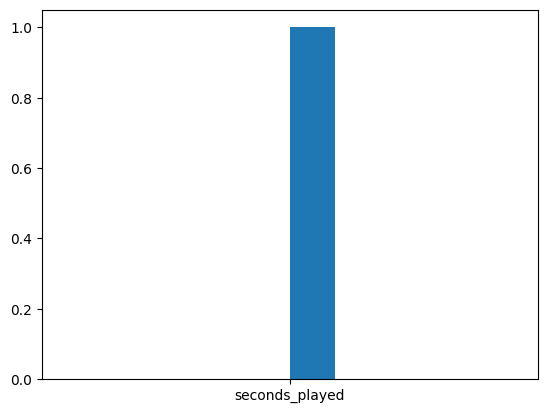

In [7]:
# Count the classes of CLASS_TARGET, describe REG_TARGET, and draw its histogram
raw_df[CLASS_TARGET].value_counts()
raw_df[REG_TARGET].describe()
plt.hist(REG_TARGET)

---
## 2. Clean the data

Your file has **four** of the six problem types below. Run **all six checks, in this order**, on a copy called `df`. A check for a problem your file doesn't have removes (or fixes) 0 rows, which is the correct result: that's how you find out which four you have.

| # | Check | Rule |
|---|---|---|
| 1 | `duplicates` | remove exact copies of an earlier row (`df.drop_duplicates()`) |
| 2 | `codes` | remove rows where session_position is -1 or tempo_bpm is 999 (codes for unknown) |
| 3 | `blanks` | remove rows with a missing value (`df.dropna()`) |
| 4 | `impossible` | remove rows where listener_age is above 100 or hour is above 23 |
| 5 | `outliers` | remove rows where track_length_sec is more than 3 standard deviations above the mean (worked out once, at this point) |
| 6 | `labels` | genre has stray capitals or spaces, e.g. 'Pop', ' indie'. Fix with .str.strip().str.lower(); don't remove the rows |

Record checks 1 to 5 in the dictionary `rows_removed` using the check's name as the key, and the number of rows you corrected in check 6 in `labels_fixed`. The pattern for a removal check is:

```
n_before = len(df)
df = df[...]                 # or df.drop_duplicates(), df.dropna()
rows_removed["blanks"] = n_before - len(df)
```

### 2.1 A working copy and an empty dictionary

In [8]:
# Make a copy of raw_df called df, and create an empty dictionary called rows_removed
df=raw_df.copy()
rows_removed={}
n_before = len(df)
df = df.drop_duplicates()

### 2.2 Check 1: duplicates

In [9]:
# Remove exact duplicate rows and record rows_removed["duplicates"]
rows_removed["duplicates"] = n_before - len(df)
print(rows_removed)

{'duplicates': 0}


### 2.3 Check 2: codes for unknown

Keep rows where `session_position` is not -1 **and** `tempo_bpm` is not 999: `df[(cond1) & (cond2)]`.

In [10]:
# Remove the rows with codes for unknown, and record rows_removed["codes"]
n_before = len(df)
df = df[(df['session_position'] != -1) & (df['tempo_bpm'] != 999)]
rows_removed["codes"] = n_before - len(df)
print(rows_removed)

{'duplicates': 0, 'codes': 0}


### 2.4 Check 3: blanks

`df.dropna()`.

In [11]:
# Remove rows with a missing value, and record rows_removed["blanks"]
n_before = len(df)
df = df.dropna()
rows_removed["blanks"] = n_before - len(df)
print(df.isna().sum().sum(), "missing values left")
print("Rows left:", len(df))
print(rows_removed)

0 missing values left
Rows left: 2967
{'duplicates': 0, 'codes': 0, 'blanks': 33}


### 2.5 Check 4: impossible values

Keep rows where `listener_age` is 100 or less **and** `hour` is 23 or less.

In [12]:
# Remove rows with impossible values, and record rows_removed["impossible"]
n_before = len(df)
df = df[(df['listener_age'] <= 100) & (df['hour'] <= 23)]
rows_removed["impossible"] = n_before - len(df)
print(rows_removed)

{'duplicates': 0, 'codes': 0, 'blanks': 33, 'impossible': 29}


### 2.6 Check 5: outliers in track_length_sec

`upper_limit = df["track_length_sec"].mean() + 3 * df["track_length_sec"].std()`, then keep rows at or below it. Apply it **once**.

In [16]:
# Work out upper_limit for track_length_sec, keep rows at or below it, and record rows_removed["outliers"]
upper_limit = df["track_length_sec"].mean() + 3 * df["track_length_sec"].std()
print("Upper limit (mean + 3 std):", round(upper_limit, 2))
n_before = len(df)
df = df[df["track_length_sec"] <= upper_limit]
rows_removed["outliers"] = n_before - len(df)
print(rows_removed)

Upper limit (mean + 3 std): 794.68
{'duplicates': 0, 'codes': 0, 'blanks': 33, 'impossible': 29, 'outliers': 30}


### 2.7 Check 6: labels

Make the corrected version, `fixed = df["genre"].str.strip().str.lower()`, count how many rows change with `(fixed != df["genre"]).sum()` into `labels_fixed`, then put `fixed` back into `df["genre"]`. No rows are removed.

In [ ]:
# Correct the genre labels, and record how many rows changed in labels_fixed


### 2.8 Which problems did your file have?

Make a list `problems_found` with the names of the checks that removed or fixed **at least one** row, for example `["duplicates", "blanks", "outliers", "labels"]`. Then print `len(raw_df)`, `len(df)` and `rows_removed`.

In [ ]:
# Create the list problems_found, then print the rows before and after cleaning and rows_removed
problems_found=["blanks",

---
## 3. Prepare the features and targets

### 3.1 Features

The finished cell below defines `make_features(data)`. It keeps the numeric columns and turns each text column into 0/1 columns (one per category), the same idea as `pd.get_dummies()` in Lab 5. It leaves out `play_id` (a label), `age_band` where it is only a grouping column, and both targets.

**Why leave out the other target?** `skipped` is worked out from `seconds_played`. If one target were a feature for the other, the model would look brilliant in the notebook and be useless in practice, because when you make a real prediction you don't know either yet. That is called **leakage**.

In [ ]:
# Finished cell: turns cleaned rows into the numeric features the models use. Don't change it
# unless you are adding features in Section 7 (and then keep it working on new rows).
NUMERIC_COLS = ["listener_age", "irish_artist", "track_length_sec", "tempo_bpm", "energy", "danceability", "valence", "track_age_years", "liked_artist", "session_position", "hour"]
CATEGORY_COLS = {
    "genre": ["pop", "hip-hop", "rock", "dance", "indie", "trad", "country"],
    "context": ["playlist", "album", "radio", "search", "shuffle"],
    "device": ["phone", "desktop", "smart_speaker"]
}


def make_features(data):
    X = data[NUMERIC_COLS].astype(float).copy()
    for col, cats in CATEGORY_COLS.items():
        dummies = pd.get_dummies(pd.Categorical(data[col], categories=cats), prefix=col, dtype=int)
        dummies.index = data.index
        X = pd.concat([X, dummies], axis=1)
    return X

### 3.2 X, the targets and the split

`X = make_features(df)`, `feature_cols = list(X.columns)`, `y_class = df[CLASS_TARGET]`, `y_reg = df[REG_TARGET]`.

Split all three **together**, with exactly these settings, so your test set matches the one used for marking:

`train_test_split(X, y_class, y_reg, test_size=0.2, random_state=42, stratify=y_class)`

It returns six things, in this order: `X_train, X_test, yc_train, yc_test, yr_train, yr_test`.

In [ ]:
# Create X, feature_cols, y_class and y_reg, then split into the six parts

### 3.3 Scale

`from sklearn.preprocessing import StandardScaler`. Fit `scaler` on `X_train` only, then make `X_train_scaled` and `X_test_scaled`. Both tasks use the same scaled features.

In [ ]:
# Fit a StandardScaler called scaler on X_train, then create X_train_scaled and X_test_scaled

---
## 4. Classification: predict `skipped`

### 4.1 Model 1: logistic regression

`from sklearn.linear_model import LogisticRegression`, `clf_1 = LogisticRegression(max_iter=1000)`, `.fit(X_train_scaled, yc_train)`, then `yc_pred_1 = clf_1.predict(X_test_scaled)`.

In [ ]:
# Create clf_1 (logistic regression), train it, and predict the test set into yc_pred_1
from sklearn.linear_model import LogisticRegression

clf_1 = LogisticRegression(max_iter=1000)
clf_1.fit(X_train_scaled, yc_train)
yc_pred_1 = clf_1.predict(X_test_scaled)

### 4.2 Score it

`from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay`. Print `accuracy_score(yc_test, yc_pred_1)` and `recall_score(yc_test, yc_pred_1)`, and draw `ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_1)` then `plt.show()`. After every chart, print the numbers it shows: anyone on the team should be able to read your results without seeing the picture.

In [ ]:
# Print the accuracy and recall of clf_1, and draw its confusion matrix
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay, confusion_matrix

print("Accuracy:", accuracy_score(yc_test, yc_pred_1))
print("Recall:", recall_score(yc_test, yc_pred_1))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_1)
plt.show()
print(confusion_matrix(yc_test, yc_pred_1)) 

### 4.3 Model 2: your choice

Pick one, train it as `clf_2`, predict into `yc_pred_2`, and score it as in 4.2.

| Model | Import | Tip |
|---|---|---|
| K-nearest neighbours | `from sklearn.neighbors import KNeighborsClassifier` | Try `n_neighbors=15` |
| Decision tree | `from sklearn.tree import DecisionTreeClassifier` | `max_depth=5`, `random_state=42` |
| Random forest | `from sklearn.ensemble import RandomForestClassifier` | `random_state=42` |
| Gradient boosting | `from sklearn.ensemble import GradientBoostingClassifier` | `random_state=42` |
| Histogram gradient boosting | `from sklearn.ensemble import HistGradientBoostingClassifier` | `random_state=42` |
| Neural network (MLP), advanced, see below | `from sklearn.neural_network import MLPClassifier` | `hidden_layer_sizes=(64, 32)`, `max_iter=1000`, `early_stopping=True`, `random_state=42` |

**Optional, advanced: a neural network.** You can use scikit-learn's multi-layer perceptron as Model 2. It is the same kind of network as in Lectures 5 and 6 (hidden layers of neurons with ReLU), in the same `.fit()` and `.predict()` style as the other models here. A team that uses one for `clf_2` or `reg_2` gets a **+5 bonus** on the notebook (the notebook mark can't go above 100). Not using one is completely fine: every other model in this table can still earn full marks.

**Don't use Keras (`tf.keras`) in this project.** The marking program can only mark scikit-learn models, so a Keras model scores 0 for this step and for the hidden rows. The brief has a side-by-side table showing how the Lecture 6 Keras code maps onto the scikit-learn version.

In [ ]:
# Import your second classifier, create clf_2, train it, and predict the test set into yc_pred_2
from sklearn.ensemble import RandomForestClassifier

clf_2 = RandomForestClassifier(random_state=42)
clf_2.fit(X_train_scaled, yc_train)
yc_pred_2 = clf_2.predict(X_test_scaled)

In [ ]:
# Print the accuracy and recall of clf_2, and draw its confusion matrix
print("Accuracy:", accuracy_score(yc_test, yc_pred_2))
print("Recall:", recall_score(yc_test, yc_pred_2))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_2)
plt.show()
print(confusion_matrix(yc_test, yc_pred_2))

### 4.4 Choose your final classifier

Set `final_clf` to `clf_1` or `clf_2`. In the Markdown cell after it, say in one or two sentences why: accuracy alone is not enough, so think about recall too.

In [ ]:
# Set final_clf to clf_1 or clf_2
final_clf = clf_2 # Change to other model if it scores better

**Why we chose it** (double-click to edit):

---
## 5. Regression: predict `seconds_played`

### 5.1 Model 1: linear regression

`from sklearn.linear_model import LinearRegression`, `reg_1 = LinearRegression()`, `.fit(X_train_scaled, yr_train)`, then `yr_pred_1 = reg_1.predict(X_test_scaled)`. This is Lab 4 again, with a different target.

In [ ]:
# Create reg_1 (linear regression), train it, and predict the test set into yr_pred_1

### 5.2 Score it

`from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score`

* MAE: `mean_absolute_error(yr_test, yr_pred_1)`, the average size of a mistake, in the target's own units
* RMSE: `np.sqrt(mean_squared_error(yr_test, yr_pred_1))`, which punishes big mistakes more
* R²: `r2_score(yr_test, yr_pred_1)`, the share of the variation the model explains (1 is perfect, 0 is no better than the average)

Then plot actual against predicted with `plt.scatter(yr_test, yr_pred_1, s=5)`, label the axes, and `plt.show()`.

In [ ]:
# Print the MAE, RMSE and R2 of reg_1, and plot actual against predicted

### 5.3 Model 2: your choice

| Model | Import | Tip |
|---|---|---|
| K-nearest neighbours | `from sklearn.neighbors import KNeighborsRegressor` | Try `n_neighbors=15` |
| Decision tree | `from sklearn.tree import DecisionTreeRegressor` | `max_depth=6`, `random_state=42` |
| Random forest | `from sklearn.ensemble import RandomForestRegressor` | `random_state=42` |
| Gradient boosting | `from sklearn.ensemble import GradientBoostingRegressor` | `random_state=42`, as in Lab 4 |
| Histogram gradient boosting | `from sklearn.ensemble import HistGradientBoostingRegressor` | `random_state=42` |
| Neural network (MLP), advanced, see below | `from sklearn.neural_network import MLPRegressor` | `hidden_layer_sizes=(64, 32)`, `max_iter=1000`, `early_stopping=True`, `random_state=42` |

**Optional, advanced: a neural network.** You can use scikit-learn's multi-layer perceptron as Model 2 here too. It is the same kind of network as in Lectures 5 and 6 (hidden layers of neurons with ReLU), in the same `.fit()` and `.predict()` style as the other models here. A team that uses one for `clf_2` or `reg_2` gets a **+5 bonus** on the notebook (the notebook mark can't go above 100). The bonus is +5 in total, not +5 per model.

**Don't use Keras (`tf.keras`) in this project.** The marking program can only mark scikit-learn models, so a Keras model scores 0 for this step and for the hidden rows. The brief has a side-by-side table showing how the Lecture 6 Keras code maps onto the scikit-learn version.

In [ ]:
# Import your second regressor, create reg_2, train it, and predict the test set into yr_pred_2

In [ ]:
# Print the MAE, RMSE and R2 of reg_2, and plot actual against predicted

### 5.4 Choose your final regressor

Set `final_reg` to `reg_1` or `reg_2`, and say why in the Markdown cell after it.

In [ ]:
# Set final_reg to reg_1 or reg_2

**Why we chose it** (double-click to edit):

---
## 6. Is it fair, and what drives it?

### 6.1 Fairness by group

Does your model work as well for every `age_band`? Get each test row's group with `group_test = df.loc[X_test.index, GROUP_COL]`. Then, using `final_clf` and `final_reg`, work out for each group: the number of test rows, the **recall** of `final_clf`, and the **MAE** of `final_reg`. Collect them in a DataFrame called `fairness` with columns `group`, `n`, `recall` and `mae`, and print it.

```
pred_c = final_clf.predict(X_test_scaled)
pred_r = final_reg.predict(X_test_scaled)
rows = []
for g in sorted(group_test.unique()):
    m = (group_test == g).to_numpy()
    rows.append({"group": g, "n": m.sum(),
                 "recall": recall_score(yc_test[m], pred_c[m]),
                 "mae": mean_absolute_error(yr_test[m], pred_r[m])})
fairness = pd.DataFrame(rows)
```

In [ ]:
# Create group_test and the fairness table, and print it

### 6.2 Which features matter most?

Permutation importance shuffles one feature at a time and measures how much worse the model gets. A feature the model relies on hurts a lot when shuffled.

```
from sklearn.inspection import permutation_importance
imp = permutation_importance(final_clf, X_test_scaled, yc_test, n_repeats=5, random_state=42)
importance = pd.Series(imp.importances_mean, index=feature_cols).sort_values(ascending=False)
```

Print the top ten, draw them as a bar chart, and store the names of the top three in a list called `top_features`.

In [ ]:
# Work out permutation importance for final_clf, show the top ten, and set top_features

### 6.3 What you found

In the cell below, write **four to six sentences** to Ceol, using **your own numbers**:

* how good each final model is, in plain terms (for example, "on average our delivery-time prediction is out by 4 minutes");
* which three features matter most, and whether that makes sense;
* whether any group is served worse, and by how much;
* what you would recommend they do with the models, and one thing they should not do with them.

**Our findings** (double-click to edit):

---
## 7. Optional: improve your models

For stronger teams. Try a new feature (add it inside `make_features`, so it also works on new rows), different settings for your models, or a third model. If you change `make_features`, re-run everything from Section 3 down. Report what you tried, and whether it helped on the **test set**, in a Markdown cell and in your presentation. Section 7 earns no marks on its own, but a better final model scores better on the hidden rows (Section F of the marking).

In [ ]:
# Optional: your improvements (leave empty if you don't try any)

---
## 8. Your answers

Fill in the dictionary below. **Use your variables, not typed-in numbers**, so the answers always match your notebook. Then run the finished cell after it.

In [ ]:
# Fill in your answers (replace each None)
answers = {
    "team_id": TEAM_ID,
    "domain": DOMAIN,
    "problems_found": None,          # your list from 2.8
    "rows_removed": None,            # your dictionary from Section 2
    "labels_fixed": None,            # from 2.7
    "rows_after_cleaning": None,     # hint: len(df)
    "clf_2_name": None,              # e.g. "Random forest"
    "accuracy_clf_1": None,
    "recall_clf_1": None,
    "accuracy_clf_2": None,
    "recall_clf_2": None,
    "final_clf": None,               # "clf_1" or "clf_2"
    "reg_2_name": None,              # e.g. "Random forest"
    "mae_reg_1": None,
    "rmse_reg_1": None,
    "mae_reg_2": None,
    "rmse_reg_2": None,
    "final_reg": None,               # "reg_1" or "reg_2"
    "recall_by_group": None,         # hint: dict(zip(fairness["group"].astype(str), fairness["recall"]))
    "mae_by_group": None,            # the same for "mae"
    "top_features": None,            # your list from 6.2
}

In [ ]:
# Finished cell: prints your answers for marking. Do not change it.
print(json.dumps(answers, indent=2, default=float))

---
**Finished?** Save as `CA2_<team code>_<domain>.ipynb`, for example `CA2_Wed-07_music.ipynb`. Choose **Kernel › Restart Kernel and Run All Cells**, check there are no errors, save, and one member uploads it to the CA2 Team Project folder on Brightspace.